In [13]:
from qiskit.quantum_info import Operator
from qiskit import QuantumCircuit
import numpy as np

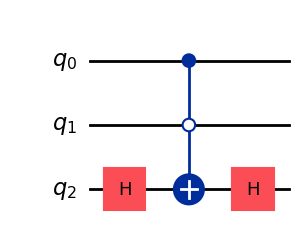

In [14]:
n=3
qc=QuantumCircuit(n)
qc.h(n-1)
qc.mcx([0,1],2,ctrl_state='01')
qc.h(n-1)
qc.draw('mpl') #mpl=Matplotlib

In [15]:
def phase_oracle(qc,m): #definizione del circuito sopra
    qc.h(n-1)
    qc.mcx([0,1],2,ctrl_state='01')
    qc.h(n-1)
    return qc

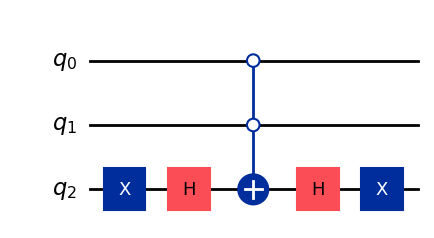

In [16]:
n=3
qc=QuantumCircuit(n)
qc.x(n-1)
qc.h(n-1)
qc.mcx([0,1],2,ctrl_state='00')
qc.h(n-1)
qc.x(n-1)
qc.draw('mpl') 

In [17]:
def diffuser(qc, n):
   qc.h(range(n))
   qc.x(n-1)
   qc.h(n-1)
   qc.mcx([0,1],2,ctrl_state='00')
   qc.h(n-1)
   qc.x(n-1)
   qc.h(range(n))
   return qc


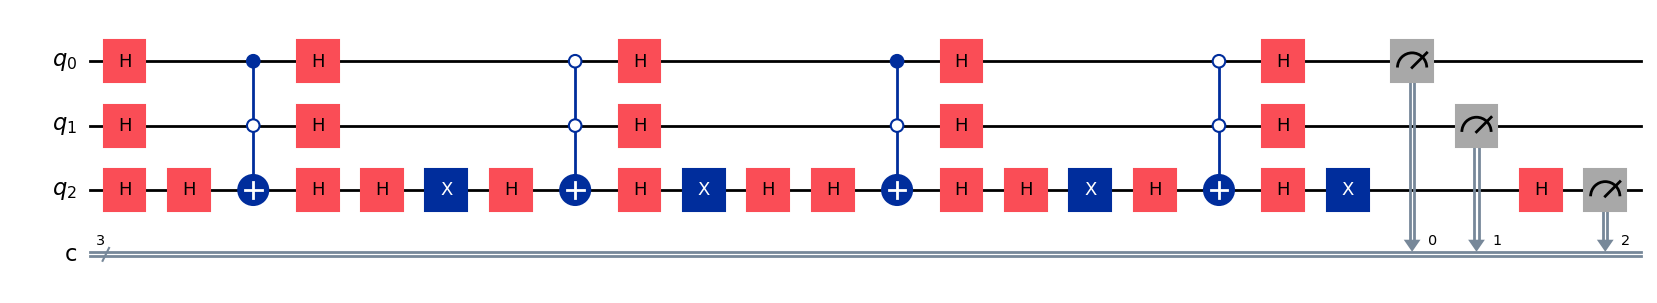

In [24]:
n=3
gr=QuantumCircuit(n,n) #QuantumCircuit(n) → Solo qubit, utile per operazioni puramente quantistiche. QuantumCircuit(n, n) → Qubit + bit classici per poter misurare i risultati.
nsol=1 #num of solutions
alpha=np.arcsin(np.sqrt(nsol/2**(n))) #determine alpha
r=round(np.pi/(4*alpha)-0.5) #determine r

gr.h(range(n)) #apply hadamard gates on all working qbits

#step 2 apply r rounds of the phase oracle and the diffuser
for j in range(r):
   
    phase_oracle(gr,n)
    diffuser(gr,n)
    #gr.append(phase_oracle(), range(n))
    #gr.append(diffuser(), range(n))

gr.measure(range(n), range(n)) #step 3: measure all qbits

gr.draw('mpl')

Result(backend_name='basic_simulator', backend_version='0.1', qobj_id='3bb39a20-bcbe-4547-983f-8d51a564c8ae', job_id='92db10a7-ec49-46e1-af24-bba0f36c1e29', success=True, results=[ExperimentResult(shots=1000, success=True, meas_level=2, data=ExperimentResultData(counts={'0x5': 954, '0x4': 9, '0x6': 8, '0x3': 8, '0x7': 1, '0x2': 7, '0x1': 5, '0x0': 8}), header=QobjExperimentHeader(qubit_labels=[['q', 0], ['q', 1], ['q', 2]], n_qubits=3, qreg_sizes=[['q', 3]], clbit_labels=[['c', 0], ['c', 1], ['c', 2]], memory_slots=3, creg_sizes=[['c', 3]], name='circuit-173', global_phase=3.141592653589793, metadata={}), status=DONE, name='circuit-173', seed_simulator=np.int32(2049052164), time_taken=0.002714872360229492)], date=None, status=COMPLETED, header=QobjHeader(backend_name='basic_simulator', backend_version='0.1'), time_taken=0.0028221607208251953)


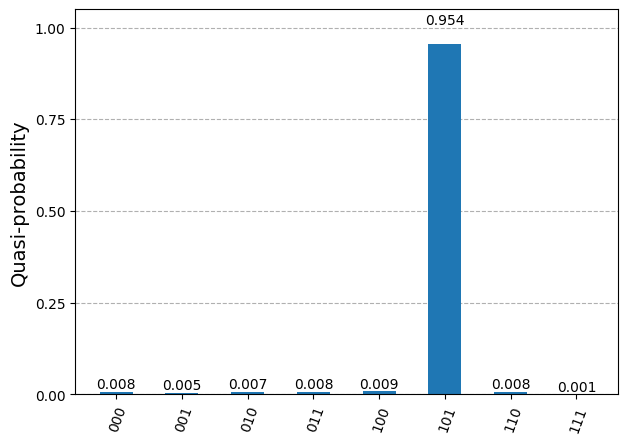

In [26]:
from qiskit.providers.basic_provider import BasicSimulator
from qiskit import transpile
simulator_basic=BasicSimulator()
gr_trsp=transpile(gr, simulator_basic)
job=simulator_basic.run(gr_trsp, shots=1000)
result=job.result()
print(result)

counts=result.get_counts()
from qiskit.visualization import plot_histogram, plot_distribution

plot_distribution(counts)

In [28]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit import transpile
backend_name="ibm_kyiv"
backend_ibm=QiskitRuntimeService().backend(backend_name)
gr_ibm=transpile(gr,backend_ibm)

In [29]:
from qiskit_ibm_runtime import SamplerV2 as Sampler
sampler=Sampler(backend_ibm)
job=sampler.run([(gr_ibm,None,1000)])
job_id=job.job_id()
print(job_id)

czkg65ra980g008hjdrg


PrimitiveResult([SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=1000, num_bits=3>)), metadata={'circuit_metadata': {}})], metadata={'execution': {'execution_spans': ExecutionSpans([DoubleSliceSpan(<start='2025-03-28 20:14:20', stop='2025-03-28 20:14:21', size=1000>)])}, 'version': 2})


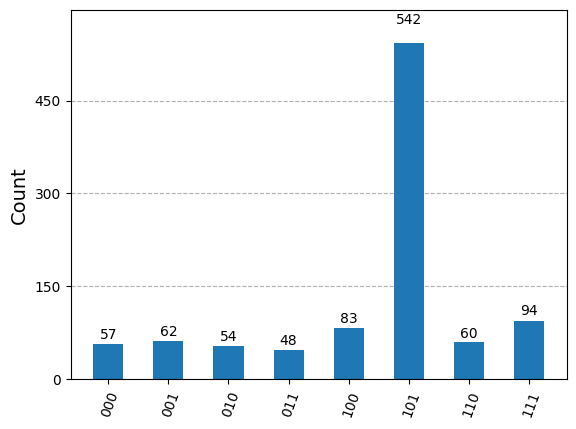

In [30]:
service=QiskitRuntimeService()
job=service.job(job_id)
result=job.result()
print(result)
counts=result[0].data.c.get_counts()
from qiskit.visualization import plot_histogram, plot_distribution

plot_histogram(counts)